# 05 – Baseline Customer Segmentation with K-Means



## 1. Import libraries

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Locate project and load RFM dataset

In [5]:
current_path = Path.cwd()
project_root = None

for candidate in [current_path, *current_path.parents]:
    if (candidate / "data" / "processed").exists():
        project_root = candidate
        break

if project_root is None:
    raise FileNotFoundError(
        "Could not find data/processed. Open this notebook from inside your project folder."
    )

input_file = project_root / "data" / "processed" / "rfm_customer_features.csv"

if not input_file.exists():
    raise FileNotFoundError(f"RFM file not found: {input_file}")

rfm = pd.read_csv(input_file)

print("Loaded:", input_file)
print("Rows:", len(rfm))
print("Columns:", rfm.columns.tolist())
display(rfm.head())

Loaded: d:\loyality_reward_optimization\data\processed\rfm_customer_features.csv
Rows: 5878
Columns: ['customer_id', 'recency', 'frequency', 'monetary', 'last_purchase_date']


,customer_id,recency,frequency,monetary,last_purchase_date
0,"12,346.00",326,12,"77,556.46",2011-01-18 10:01:00
1,"12,347.00",3,8,"4,921.53",2011-12-07 15:52:00
2,"12,348.00",76,5,"2,019.40",2011-09-25 13:13:00
3,"12,349.00",19,4,"4,428.69",2011-11-21 09:51:00
4,"12,350.00",311,1,334.40,2011-02-02 16:01:00


## 3. Validate RFM input

In [6]:
required_columns = ["customer_id", "recency", "frequency", "monetary"]
missing_columns = [col for col in required_columns if col not in rfm.columns]

if missing_columns:
    raise ValueError("Missing columns: " + ", ".join(missing_columns))

rfm = rfm[required_columns].copy()

for col in ["recency", "frequency", "monetary"]:
    rfm[col] = pd.to_numeric(rfm[col], errors="coerce")

if rfm[required_columns].isna().any().any():
    raise ValueError("RFM input contains missing or non-numeric values.")

if not rfm["customer_id"].is_unique:
    raise ValueError("There must be exactly one row per customer.")

if (rfm[["recency", "frequency", "monetary"]] <= 0).any().any():
    raise ValueError("RFM values must be positive for this workflow.")

print("RFM input validation: PASSED")
print("Unique customers:", rfm["customer_id"].nunique())
display(rfm[["recency", "frequency", "monetary"]].describe().T)

RFM input validation: PASSED
Unique customers: 5878


,count,mean,std,min,25%,50%,75%,max
recency,"5,878.00",201.87,209.35,1.00,26.00,96.00,380.00,739.00
frequency,"5,878.00",6.29,13.01,1.00,1.00,3.00,7.00,398.00
monetary,"5,878.00","2,955.90","14,440.85",2.95,342.28,867.74,"2,248.30","580,987.04"


## 4. Inspect RFM distributions

RFM values are often right-skewed: a small number of customers may have very high Frequency or Monetary values. Check the histograms before clustering.

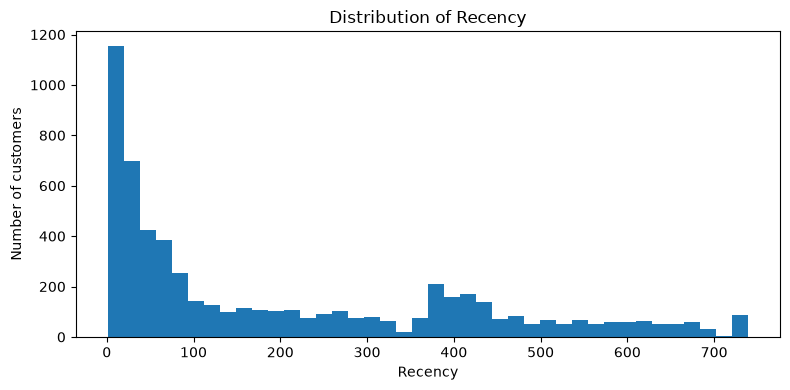

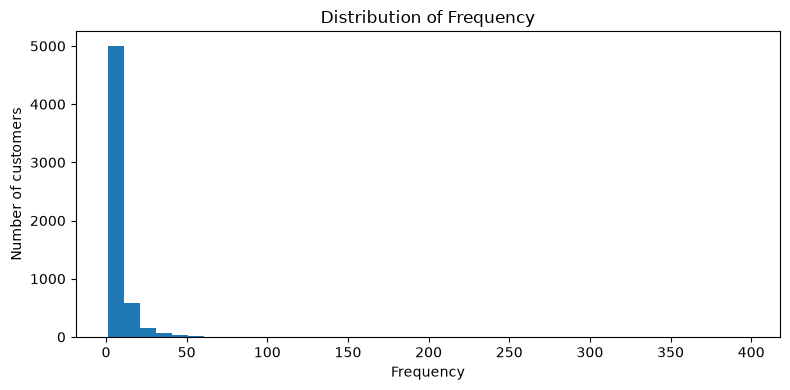

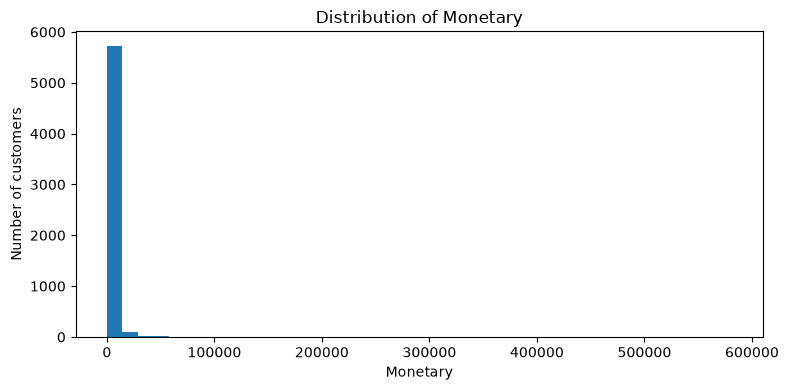

In [7]:
for feature in ["recency", "frequency", "monetary"]:
    plt.figure(figsize=(8, 4))
    plt.hist(rfm[feature], bins=40)
    plt.title(f"Distribution of {feature.title()}")
    plt.xlabel(feature.title())
    plt.ylabel("Number of customers")
    plt.tight_layout()
    plt.show()

## 5. Apply log transformation


Log-transformed feature summary:


,count,mean,std,min,25%,50%,75%,max
recency,"5,878.00",4.47,1.53,0.69,3.30,4.57,5.94,6.61
frequency,"5,878.00",1.55,0.81,0.69,0.69,1.39,2.08,5.99
monetary,"5,878.00",6.82,1.39,1.37,5.84,6.77,7.72,13.27


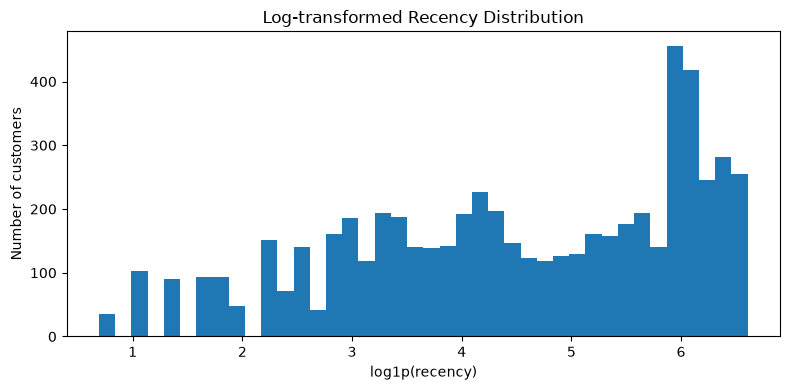

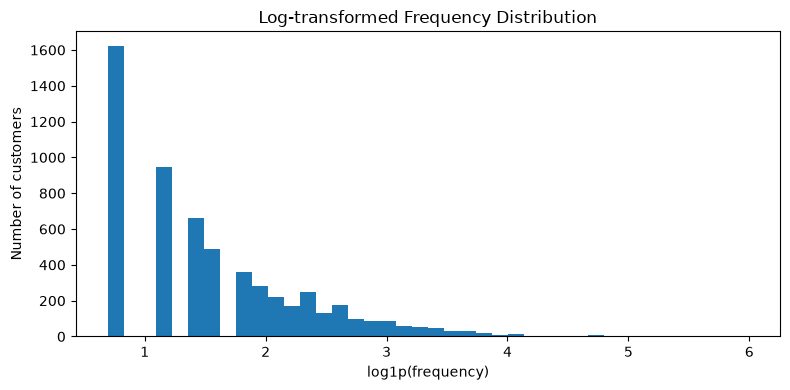

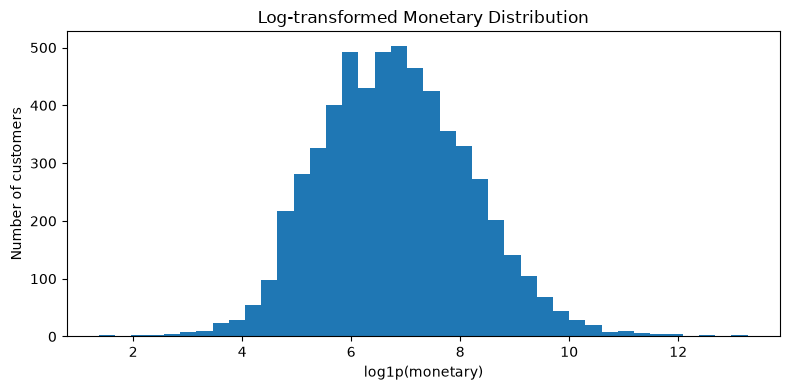

In [8]:
rfm_features = rfm[["recency", "frequency", "monetary"]].copy()

log_features = np.log1p(rfm_features)

print("Log-transformed feature summary:")
display(log_features.describe().T)

for feature in log_features.columns:
    plt.figure(figsize=(8, 4))
    plt.hist(log_features[feature], bins=40)
    plt.title(f"Log-transformed {feature.title()} Distribution")
    plt.xlabel(f"log1p({feature})")
    plt.ylabel("Number of customers")
    plt.tight_layout()
    plt.show()

## 6. Scale the transformed features

In [9]:
scaler = StandardScaler()
scaled_features = scaler.fit_transform(log_features)

scaled_df = pd.DataFrame(
    scaled_features,
    columns=["recency_scaled", "frequency_scaled", "monetary_scaled"]
)

print("Scaled feature means (approximately 0):")
display(scaled_df.mean().to_frame("mean"))

print("Scaled feature standard deviations (approximately 1):")
display(scaled_df.std(ddof=0).to_frame("std"))

Scaled feature means (approximately 0):


,mean
recency_scaled,0.00
frequency_scaled,0.00
monetary_scaled,0.00


Scaled feature standard deviations (approximately 1):


,std
recency_scaled,1.00
frequency_scaled,1.00
monetary_scaled,1.00


## 7. Compare possible cluster counts


In [10]:
k_values = range(2, 9)
inertia_values = []
silhouette_values = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(scaled_features)

    inertia_values.append(model.inertia_)
    silhouette_values.append(
        silhouette_score(scaled_features, labels, sample_size=10000, random_state=42)
    )

evaluation = pd.DataFrame({
    "k": list(k_values),
    "inertia": inertia_values,
    "silhouette_score_sample": silhouette_values
})

display(evaluation)
evaluation.to_csv(
    project_root / "data" / "processed" / "kmeans_cluster_evaluation.csv",
    index=False
)

,k,inertia,silhouette_score_sample
0,2,"8,577.11",0.44
1,3,"6,336.79",0.35
2,4,"4,895.41",0.37
3,5,"4,069.63",0.34
4,6,"3,535.11",0.33
5,7,"3,170.92",0.30
6,8,"2,883.12",0.30


## 8. Plot elbow and silhouette results

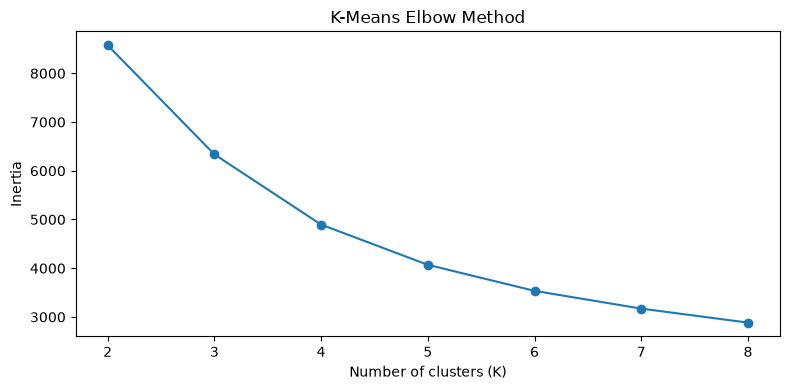

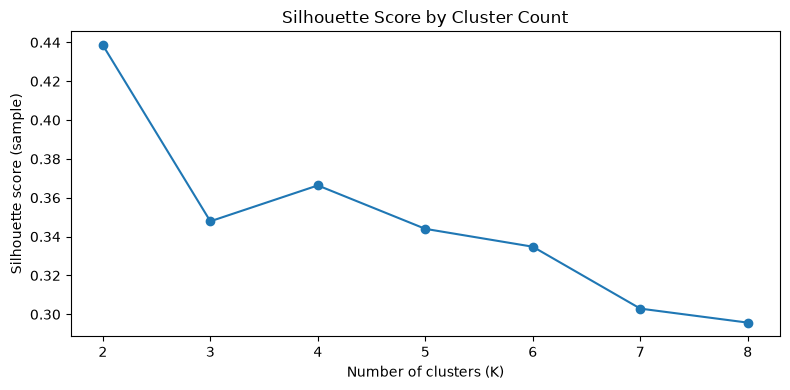

In [11]:
plt.figure(figsize=(8, 4))
plt.plot(evaluation["k"], evaluation["inertia"], marker="o")
plt.title("K-Means Elbow Method")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.tight_layout()
plt.savefig(
    project_root / "data" / "processed" / "kmeans_elbow.png",
    dpi=150
)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(
    evaluation["k"],
    evaluation["silhouette_score_sample"],
    marker="o"
)
plt.title("Silhouette Score by Cluster Count")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette score (sample)")
plt.xticks(list(k_values))
plt.tight_layout()
plt.savefig(
    project_root / "data" / "processed" / "kmeans_silhouette.png",
    dpi=150
)
plt.show()

## 9. Select K and train the baseline model


In [12]:
best_k = int(
    evaluation.loc[
        evaluation["silhouette_score_sample"].idxmax(), "k"
    ]
)

print("K with highest sampled silhouette score:", best_k)

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

rfm["cluster"] = kmeans.fit_predict(scaled_features)

print("K-Means model trained.")
print("Cluster counts:")
display(rfm["cluster"].value_counts().sort_index().to_frame("customer_count"))

K with highest sampled silhouette score: 2
K-Means model trained.
Cluster counts:


,customer_count
cluster,
0,3546
1,2332


## 10. Create cluster profiles using original RFM values


In [13]:
cluster_summary = (
    rfm.groupby("cluster")
    .agg(
        customer_count=("customer_id", "count"),
        avg_recency=("recency", "mean"),
        median_recency=("recency", "median"),
        avg_frequency=("frequency", "mean"),
        median_frequency=("frequency", "median"),
        avg_monetary=("monetary", "mean"),
        median_monetary=("monetary", "median")
    )
    .round(2)
    .reset_index()
)

cluster_summary["customer_percentage"] = (
    cluster_summary["customer_count"] / len(rfm) * 100
).round(2)

display(cluster_summary)
cluster_summary.to_csv(
    project_root / "data" / "processed" / "rfm_cluster_summary.csv",
    index=False
)

,cluster,customer_count,avg_recency,median_recency,avg_frequency,median_frequency,avg_monetary,median_monetary,customer_percentage
0,0,3546,301.05,291.50,2.09,2.00,611.55,414.17,60.33
1,1,2332,51.05,24.00,12.67,8.00,"6,520.68","2,852.50",39.67


## 11. Visualise cluster profiles

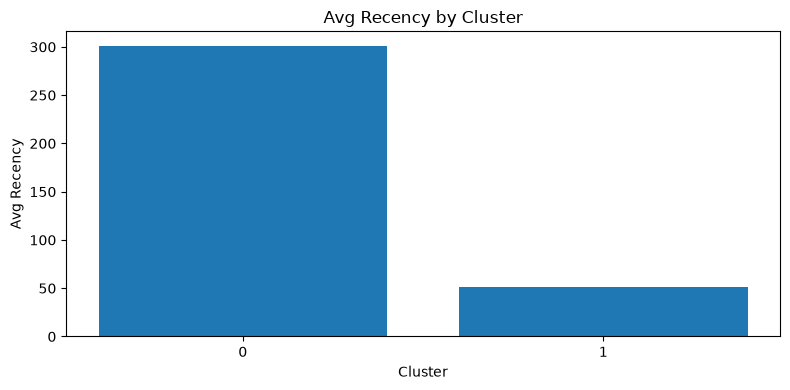

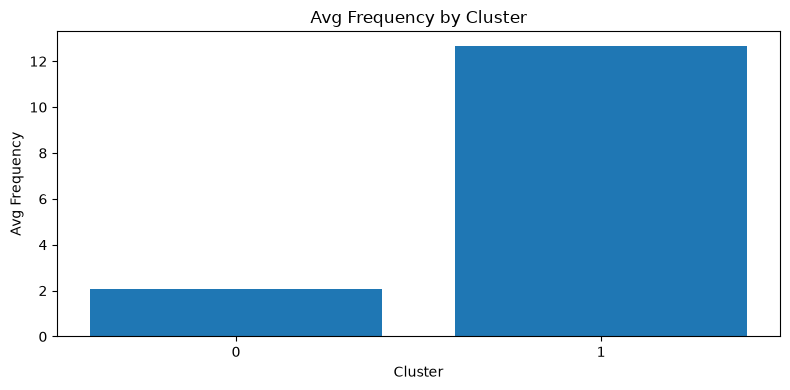

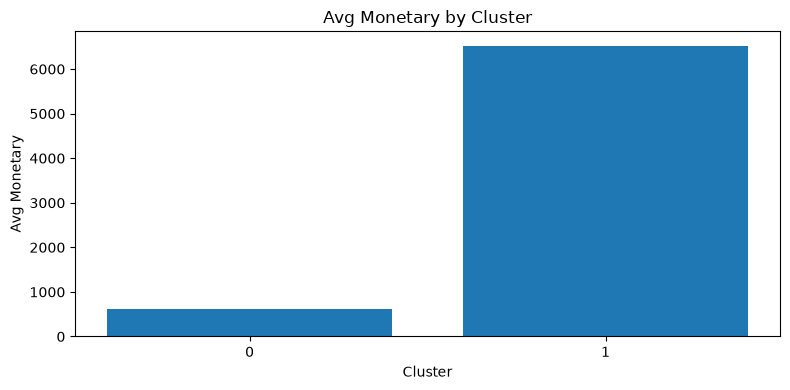

In [14]:
profile_columns = ["avg_recency", "avg_frequency", "avg_monetary"]

for column in profile_columns:
    plt.figure(figsize=(8, 4))
    plt.bar(
        cluster_summary["cluster"].astype(str),
        cluster_summary[column]
    )
    plt.title(f"{column.replace('_', ' ').title()} by Cluster")
    plt.xlabel("Cluster")
    plt.ylabel(column.replace("_", " ").title())
    plt.tight_layout()
    plt.savefig(
        project_root / "data" / "processed" / f"{column}_by_cluster.png",
        dpi=150
    )
    plt.show()

## 12. Save customer segments as CSV

In [15]:
output_file = project_root / "data" / "processed" / "customer_rfm_segments.csv"

rfm.to_csv(output_file, index=False)

# Reload and validate the saved output.
segments_check = pd.read_csv(output_file)

assert len(segments_check) == len(rfm)
assert segments_check["customer_id"].is_unique
assert segments_check["cluster"].notna().all()

print("Saved:", output_file)
print("Rows:", len(segments_check))
print("Unique customers:", segments_check["customer_id"].nunique())
print("Clusters:", sorted(segments_check["cluster"].unique()))
print("CSV save and reload validation: PASSED")

display(segments_check.head())

Saved: d:\loyality_reward_optimization\data\processed\customer_rfm_segments.csv
Rows: 5878
Unique customers: 5878
Clusters: [np.int64(0), np.int64(1)]
CSV save and reload validation: PASSED


,customer_id,recency,frequency,monetary,cluster
0,"12,346.00",326,12,"77,556.46",1
1,"12,347.00",3,8,"4,921.53",1
2,"12,348.00",76,5,"2,019.40",1
3,"12,349.00",19,4,"4,428.69",1
4,"12,350.00",311,1,334.40,0


K-MEANS EVALUATION
----------------------------------------
Silhouette Score: 0.4385
Davies-Bouldin Score: 0.8719
Calinski-Harabasz Score: 6204.70

Cluster Distribution:


cluster
0    3546
1    2332
Name: count, dtype: int64

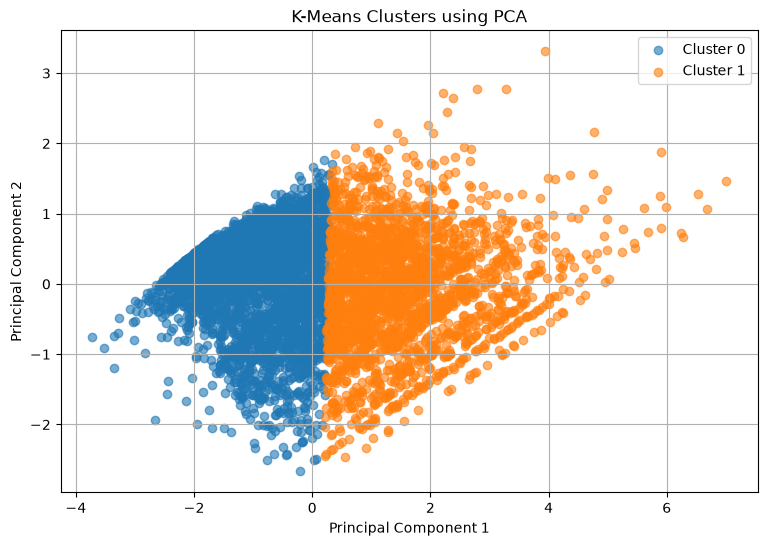


PCA explained variance: 95.10%


In [16]:
# K-Means Clustering Quality Evaluation

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from sklearn.decomposition import PCA

# 1. Evaluation Metrics
silhouette = silhouette_score(scaled_features, rfm["cluster"])
davies_bouldin = davies_bouldin_score(scaled_features, rfm["cluster"])
calinski_harabasz = calinski_harabasz_score(scaled_features, rfm["cluster"])

print("K-MEANS EVALUATION")
print("-" * 40)
print(f"Silhouette Score: {silhouette:.4f}")
print(f"Davies-Bouldin Score: {davies_bouldin:.4f}")
print(f"Calinski-Harabasz Score: {calinski_harabasz:.2f}")

# 2. Cluster Distribution
print("\nCluster Distribution:")
display(rfm["cluster"].value_counts().sort_index())

# 3. PCA Visualization (3D features -> 2D)
pca = PCA(n_components=2)
pca_features = pca.fit_transform(scaled_features)

plt.figure(figsize=(9, 6))

for cluster in sorted(rfm["cluster"].unique()):
    mask = rfm["cluster"] == cluster
    plt.scatter(
        pca_features[mask, 0],
        pca_features[mask, 1],
        label=f"Cluster {cluster}",
        alpha=0.6
    )

plt.title("K-Means Clusters using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid(True)
plt.show()

print(
    f"\nPCA explained variance: "
    f"{pca.explained_variance_ratio_.sum() * 100:.2f}%"
)
